# Resultados de tópicos sobre el corpus completo: 84.479 reseñas

G0, G3 y R2 ya se ejecutaron desde el CLI mediante ZenML y MLflow sobre las **84.479 reseñas** del snapshot verificado. Esta libreta lee sus artefactos para comparar cobertura, tamaños, recursos y ejemplos. No ajusta modelos ni genera embeddings.

G0 usa selección `eom` de HDBSCAN y G3 usa `leaf`. R2 aplica KeyBERTInspired + MMR al G3 completo, conservando sus pertenencias. Procesar todo el corpus no equivale a evaluar exhaustivamente la calidad de sus tópicos. La revisión de ejemplos sigue siendo exploratoria.


## 1. Verificando el protocolo y los resultados

Usamos identidades explícitas, sin buscar la última ejecución. Las funciones de lectura y comparación son las mismas que utiliza el CLI. El protocolo conserva las entradas, versiones y límites del experimento.


In [1]:
import json
import os
from datetime import datetime, timezone
from html import escape
from pathlib import Path
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

from voc.datasets.shared.manifest import file_hash
from voc.embeddings.shared.contracts import canonical_json
from voc.topics import read_topics
from voc.topics.comparison import compare_assignments, review_sample
from voc_ml.topics.full_corpus import inspect_full
from voc_ml.topics.store import TopicRunStore

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/voc").is_dir() and (p / "pyproject.toml").is_file())
store = TopicRunStore(os.environ.get("VOC_DATA_DIR", REPO / "data"))
STUDY_ID = "1d255e30-7273-427f-b1a1-4cb70912faec"
PROTOCOL_SHA256 = "1884869f428e6fc7af713035409086f759d9cbcaf9da63dd9755518044452309"
REFERENCES = {
    "G0": {"run_id": "cac26377-d4f4-4f8b-8264-a39fd0812bc0",
           "manifest_sha256": "39d574545713051bbb9fb177e128dc5883e4bf0c8a7526595244d9a2fd99258b"},
    "G3": {"run_id": "05f1f058-fff3-497a-b9d7-5ede22030138",
           "manifest_sha256": "98452db63615d4d3535af99d50b87646d87c63d2f8ac6819f2deadc34e3b3d73"},
    "R2": {"run_id": "86ba2e67-cf1f-484a-bfde-fa20c4dd7f76",
           "manifest_sha256": "9bdd876eb46614031ac8900c26dca564d6c275a342f6841bbef44b84978b20fd"},
}
study = inspect_full(store=store)
assert study["study_id"] == STUDY_ID
assert study["protocol_sha256"] == PROTOCOL_SHA256
bundles, runs = {}, {}
for variant, ref in REFERENCES.items():
    entry = study["entries"][variant]
    assert entry["state"] == "completed"
    assert all(entry[key] == value for key, value in ref.items())
    bundles[variant] = read_topics(store.directory(ref["run_id"]) / "release",
                                  manifest_sha256=ref["manifest_sha256"])
    runs[variant] = store.load(ref["run_id"])
    assert runs[variant]["separate_process_read"] == "passed"
    assert runs[variant]["corpus_protocol_sha256"] == PROTOCOL_SHA256
print("Tres releases verificados. Filas por resultado:", len(bundles["G0"].reviews))
print("Protocolo:", PROTOCOL_SHA256)

assert all(len(bundle.reviews) == 84479 for bundle in bundles.values())
assert study["protocol"]["input"]["selection"]["mode"] == "full"
assert study["protocol"]["input"]["selection_sha256"] == study["protocol"]["input"]["population_selection_sha256"]


Tres releases verificados. Filas por resultado: 84479
Protocolo: 1884869f428e6fc7af713035409086f759d9cbcaf9da63dd9755518044452309


## 2. Cobertura y granularidad

Un mayor número de tópicos no demuestra mayor utilidad. Observa cuántas reseñas reciben asignación y cómo cambian los tamaños. Los registros con tópico `-1` siguen en el resultado, aunque no pertenezcan a un grupo identificado.

La curva de tamaños usa escala logarítmica para mostrar tanto los grupos grandes como los pequeños. Cada posición corresponde al orden por tamaño de su propia ejecución, no al mismo tópico entre configuraciones.


,rows,topic_count,unassigned_rows,unassigned_fraction,minimum_topic_size,median_topic_size,maximum_topic_size
variant,,,,,,,
G0,84479,1810,25794,0.305330,10,24.0,1060
G3,84479,2199,33280,0.393944,10,20.0,151
R2,84479,2199,33280,0.393944,10,20.0,151


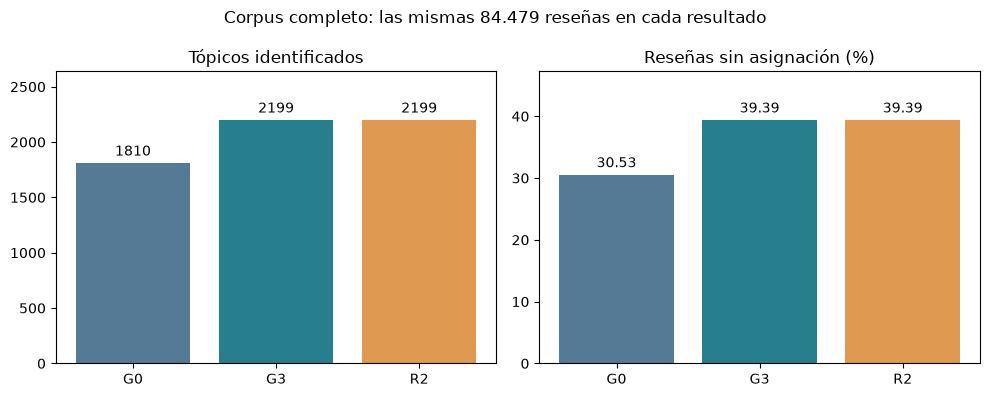

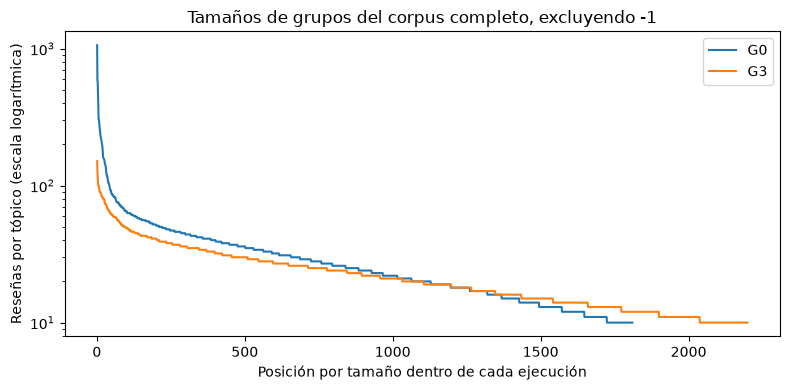

In [2]:
summary = pd.DataFrame(study["summaries"]).set_index("variant").loc[list(REFERENCES)]
display(summary[["rows", "topic_count", "unassigned_rows", "unassigned_fraction",
                 "minimum_topic_size", "median_topic_size", "maximum_topic_size"]])
figures = {}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, column, title, scale in [
    (axes[0], "topic_count", "Tópicos identificados", 1),
    (axes[1], "unassigned_fraction", "Reseñas sin asignación (%)", 100),
]:
    values = summary[column] * scale
    bars = ax.bar(summary.index, values, color=["#557a95", "#277f8e", "#df9950"])
    ax.bar_label(bars, labels=[f"{x:.2f}" if scale == 100 else str(int(x)) for x in values], padding=3)
    ax.set_title(title)
    ax.set_ylim(0, values.max() * 1.2)
fig.suptitle("Corpus completo: las mismas 84.479 reseñas en cada resultado")
fig.tight_layout()
figures["corpus-cobertura"] = fig
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for offset, variant in enumerate(["G0", "G3"]):
    sizes = np.sort(summary.loc[variant, "topic_sizes"])[::-1]
    ax.plot(np.arange(1, len(sizes) + 1), sizes, label=variant)
ax.set(xlabel="Posición por tamaño dentro de cada ejecución", ylabel="Reseñas por tópico",
       title="Tamaños de grupos del corpus completo, excluyendo -1")
ax.set_yscale("log")
ax.set_ylabel("Reseñas por tópico (escala logarítmica)")
ax.legend()
fig.tight_layout()
figures["corpus-tamanos"] = fig
plt.show()


## 3. Comparando pertenencias

El ARI mide concordancia entre particiones, no calidad semántica. Una comparación incluye `-1` como un grupo. La otra considera únicamente las reseñas asignadas por ambos resultados y declara su denominador. Los números de tópico no identifican el mismo tema entre G0 y G3.

En R2 verificamos una condición diferente: las asignaciones, coordenadas y referencias de evidencia deben conservarse exactamente respecto a G3.

**Límite de interpretación:** G0 y G3 son ajustes completos independientes. Aunque conservan la misma configuración de UMAP, sus coordenadas guardadas difieren. La comparación describe las salidas obtenidas y no aísla exclusivamente el efecto de `eom` frente a `leaf` sobre una reducción fija. No se ha diagnosticado aquí la causa de esa diferencia.


In [3]:
comparisons = pd.DataFrame([
    {"comparison": "G0 → G3", **compare_assignments(bundles["G0"], bundles["G3"])},
    {"comparison": "G3 → R2", **compare_assignments(bundles["G3"], bundles["R2"])},
])
display(comparisons.drop(columns="unassigned_policy"))
assert bundles["G3"].assignments.equals(bundles["R2"].assignments)
assert np.array_equal(bundles["G3"].coordinates, bundles["R2"].coordinates)
assert {t["topic_id"]: t["evidence_ids"] for t in bundles["G3"].topics} == {
    t["topic_id"]: t["evidence_ids"] for t in bundles["R2"].topics
}
print("R2 conserva pertenencias, coordenadas y evidencia de G3.")

reduction_check = {
    "effective_configuration_equal": bundles["G0"].execution["fit"]["effective_reduction"] == bundles["G3"].execution["fit"]["effective_reduction"],
    "coordinates_equal": bool(np.array_equal(bundles["G0"].coordinates, bundles["G3"].coordinates)),
    "interpretation": "comparación de ajustes completos, no aislamiento de HDBSCAN sobre coordenadas fijas",
}
print(json.dumps(reduction_check, ensure_ascii=False, indent=2))


,comparison,rows,ari_including_unassigned,ari_assigned_intersection,assigned_intersection_rows,became_assigned,became_unassigned
0,G0 → G3,84479,0.439875,0.756689,46552,4647,12133
1,G3 → R2,84479,1.000000,1.000000,51199,0,0


R2 conserva pertenencias, coordenadas y evidencia de G3.
{
  "effective_configuration_equal": true,
  "coordinates_equal": false,
  "interpretation": "comparación de ajustes completos, no aislamiento de HDBSCAN sobre coordenadas fijas"
}


## 4. Recursos observados

Distinguimos el RSS del worker, el RSS sumado de los procesos de la operación y el consumo del cgroup del contenedor. El segundo puede contar páginas compartidas más de una vez. El tercero también incluye servicios y kernels ajenos a ese ajuste. No deben sumarse.

La supervisión toma muestras y cancela si se supera un umbral. No impone un límite duro de memoria. Estas medidas describen una ejecución de cada operación sobre el corpus completo. El tiempo de R2 es adicional al ajuste de G3. No son promedios de un benchmark.


,preparation_seconds,worker_seconds,export_seconds,total_seconds,worker_rss_gib,group_rss_gib,cgroup_gib
variant,,,,,,,
G0,2.083,86.363,1.651,94.410,1.997,2.693,7.065
G3,1.957,83.939,1.614,91.557,2.001,2.700,6.569
R2,1.062,101.049,1.964,108.329,2.241,2.948,6.946


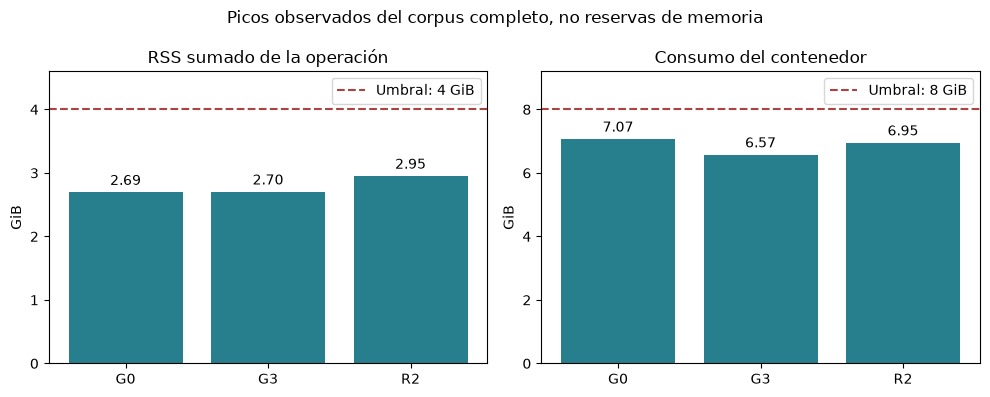

In [4]:
resource_rows = []
for variant, run in runs.items():
    supervision = run["supervision"]
    resource_rows.append({
        "variant": variant,
        "preparation_seconds": run["preparation_seconds"],
        "worker_seconds": run["worker_wall_seconds"],
        "export_seconds": run["export_seconds"],
        "total_seconds": supervision["wall_seconds"],
        "worker_rss_gib": run["fit"]["peak_worker_rss_bytes"] / 2**30,
        "group_rss_gib": supervision["peak_group_rss_bytes"] / 2**30,
        "cgroup_gib": supervision["peak_cgroup_bytes"] / 2**30,
    })
resources = pd.DataFrame(resource_rows).set_index("variant")
display(resources.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, column, limit, label in [
    (axes[0], "group_rss_gib", 4, "RSS sumado de la operación"),
    (axes[1], "cgroup_gib", 8, "Consumo del contenedor"),
]:
    bars = ax.bar(resources.index, resources[column], color="#277f8e")
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.axhline(limit, linestyle="--", color="#ac4343", label=f"Umbral: {limit} GiB")
    ax.set(title=label, ylabel="GiB", ylim=(0, limit * 1.15))
    ax.legend()
fig.suptitle("Picos observados del corpus completo, no reservas de memoria")
fig.tight_layout()
figures["corpus-memoria"] = fig
plt.show()


## 5. Revisando palabras y reseñas completas

La pauta conserva los tres grupos mayores y hasta tres adicionales seleccionados con semilla 42. Muestra hasta tres textos distintos de evidencia por grupo. No selecciona ejemplos porque favorezcan una variante.

Primero revisa G3 y R2 sobre los mismos grupos y reseñas. Observa si las palabras aluden a una funcionalidad, si concuerdan con el texto y si siguen siendo genéricas. Una palabra como «transferencia» puede ayudar a interpretar el grupo, pero no demuestra que todas sus reseñas traten ese asunto. Los ejemplos no sustituyen la revisión de todos los miembros.


In [5]:
reviews = {key: review_sample(bundles[key], seed=42) for key in ["G0", "G3"]}

def paragraph(text):
    return '<p style="white-space:pre-wrap;overflow-wrap:anywhere">' + escape(str(text)) + '</p>'

def show_topic(topic, variant, refined=None):
    content = f"<h3>{escape(variant)} · tópico {topic['topic_id']} · {topic['size']} reseñas</h3>"
    content += "<b>c-TF-IDF</b>" + paragraph(", ".join(k["term"] for k in topic["keywords"]))
    if refined is not None:
        content += "<b>KeyBERTInspired + MMR</b>" + paragraph(", ".join(k["term"] for k in refined["keywords"]))
    for evidence in topic["evidence"]:
        content += "<b>ID:</b> " + escape(evidence["record_id"]) + paragraph(evidence["model_text"])
    display(HTML(content + "<hr>"))

for topic in reviews["G3"]["topics"]:
    show_topic(topic, "G3 / R2", bundles["R2"].topic(topic["topic_id"]))


### Contrastando con G0 y con las reseñas sin asignación

La revisión de G0 aplica la misma pauta, pero sus grupos son distintos. Después lee cinco casos sin asignación de G3 para reconocer qué tipo de información queda fuera de sus tópicos.


In [6]:
for topic in reviews["G0"]["topics"]:
    show_topic(topic, "G0")

lookup = bundles["G3"].reviews.set_index("record_id")
display(HTML("<h3>G3: cinco reseñas sin asignación</h3>"))
for record_id in reviews["G3"]["unassigned_ids"]:
    display(HTML("<b>ID:</b> " + escape(record_id) + paragraph(lookup.loc[record_id, "model_text"])))


## 6. Registrando la revisión

Completa autor y observaciones después de leer los ejemplos. Indica si aparecen funcionalidades concretas, qué cambia entre G3 y R2 y qué información útil queda entre las reseñas sin asignación. No es necesario elegir un ganador ni asignar puntuaciones. Las notas documentan lo observado sin abrir nuevos ajustes.


In [7]:
REVIEW_FILE = store.root / "reports/topics/corpus/full-review.json"
review = json.loads(REVIEW_FILE.read_text()) if REVIEW_FILE.exists() else {
    "study_id": STUDY_ID,
    "protocol_sha256": PROTOCOL_SHA256,
    "reviewer": None,
    "observations": None,
    "decision": None,
    "scope": "revisión exploratoria de ejemplos fijados, no evaluación exhaustiva",
}
assert review["study_id"] == STUDY_ID and review["protocol_sha256"] == PROTOCOL_SHA256
# Completa estos campos o comparte tus observaciones en el chat.
# review["reviewer"] = "..."
# review["observations"] = "..."
# review["decision"] = "..."
print(json.dumps(review, ensure_ascii=False, indent=2))


{
  "study_id": "1d255e30-7273-427f-b1a1-4cb70912faec",
  "protocol_sha256": "1884869f428e6fc7af713035409086f759d9cbcaf9da63dd9755518044452309",
  "reviewer": null,
  "observations": null,
  "decision": null,
  "scope": "revisión exploratoria de ejemplos fijados, no evaluación exhaustiva"
}


## 7. Exportando evidencia para el artículo

Exportamos las tablas y figuras para preparar el reporte. Los ejemplos y las notas privadas permanecen bajo `data/`.


In [8]:
folder = store.root / "reports/topics/corpus" / STUDY_ID / (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid4().hex[:8]
)
folder.mkdir(parents=True, exist_ok=False)
summary.drop(columns=["topic_sizes", "supervision"], errors="ignore").to_csv(folder / "resumen.csv")
resources.to_csv(folder / "recursos.csv")
comparisons.to_csv(folder / "comparaciones.csv", index=False)
for name, figure in figures.items():
    figure.savefig(folder / f"{name}.png", dpi=180, bbox_inches="tight")
    figure.savefig(folder / f"{name}.pdf", bbox_inches="tight")
(folder / "ejemplos-privados.json").write_bytes(canonical_json(reviews))
(folder / "revision.json").write_bytes(canonical_json(review))
(folder / "comparacion-reduccion.json").write_bytes(canonical_json(reduction_check))
if all(isinstance(review.get(k), str) and review[k].strip()
       for k in ["reviewer", "observations", "decision"]):
    REVIEW_FILE.parent.mkdir(parents=True, exist_ok=True)
    REVIEW_FILE.write_bytes(canonical_json(review))
provenance = {
    "study_id": STUDY_ID, "protocol_sha256": PROTOCOL_SHA256,
    "population_scope": "full-84479", "references": REFERENCES,
    "notebook": "reports/topics/resultados-del-corpus-completo.ipynb",
    "notebook_sha256": file_hash(REPO / "reports/topics/resultados-del-corpus-completo.ipynb"),
    "files": {p.name: {"sha256": file_hash(p), "bytes": p.stat().st_size}
              for p in sorted(folder.iterdir()) if p.is_file()},
}
(folder / "manifest.json").write_bytes(canonical_json(provenance))
print("Evidencia exportada:", folder)


Evidencia exportada: /workspace/data/reports/topics/corpus/1d255e30-7273-427f-b1a1-4cb70912faec/20261103T221954Z-d4d28363


## Conclusión

El corpus completo permite describir la cobertura y granularidad obtenidas sobre el snapshot fijado. La utilidad para reconocer problemas de la app requiere leer palabras y reseñas, incluidos casos sin grupo. R2 mantiene las pertenencias de G3 y permite estudiar el cambio de representación sobre el mismo agrupamiento.

Conservamos la exploración de 1.000 registros y el piloto de 5.000 como antecedentes. Sus cifras no se sustituyen ni se mezclan con estas. Las figuras exportadas y las observaciones revisadas servirán para actualizar el artículo antes de continuar con las descripciones mediante LLM.
